In [1]:
import numpy as np 
import pandas as pd



import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub


/kaggle/input/datasets/ipythonx/mvtec-ad/license.txt
/kaggle/input/datasets/ipythonx/mvtec-ad/readme.txt
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/license.txt
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/readme.txt
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/000_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/001_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/002_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/003_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/004_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/005_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/006_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/007_mask.png
/kaggle/input/datasets/ipythonx/mvtec-ad/bottle/ground_truth/broken_large/008_ma

In [ ]:
import os, glob, random
import numpy as np, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = "/kaggle/input/datasets/ipythonx/mvtec-ad/bottle"
SIZE = 256

# ---------- 1. Building the list of masks defect and good masking ----------
def defect_pairs():
    pairs = []
    for cat in ["broken_large", "broken_small", "contamination"]:
        for img in sorted(glob.glob(f"{ROOT}/test/{cat}/*.png")):
            name = os.path.basename(img).replace(".png", "_mask.png")
            pairs.append((img, f"{ROOT}/ground_truth/{cat}/{name}", cat))
    return pairs

def good_pairs(folder):
    return [(p, None, "good") for p in sorted(glob.glob(f"{ROOT}/{folder}/good/*.png"))]

In [3]:
# ---------- 2. Dataset loading and augumentation ----------
class SegDataset(Dataset):
    def __init__(self, pairs, augment=False):
        self.pairs, self.augment = pairs, augment
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        img_path, mask_path, _ = self.pairs[i]
        img = Image.open(img_path).convert("RGB").resize((SIZE, SIZE))
        if mask_path:
            mask = Image.open(mask_path).convert("L").resize((SIZE, SIZE), Image.NEAREST)
        else:
            mask = Image.new("L", (SIZE, SIZE), 0)          # good image = empty mask black background
        img = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy((np.array(mask) > 0).astype(np.float32)).unsqueeze(0)
        if self.augment:
            if random.random() < 0.5: img, mask = img.flip(-1), mask.flip(-1)
            if random.random() < 0.5: img, mask = img.flip(-2), mask.flip(-2)
            k = random.randint(0, 3)
            img, mask = torch.rot90(img, k, (1, 2)), torch.rot90(mask, k, (1, 2))
        return img, mask

In [5]:
# ---------- 3. U-Net (encoder decoder downsampling and upsampling to check and predict the defect place----------
class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, b=16):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.d1, self.d2 = DoubleConv(3, b), DoubleConv(b, 2*b)
        self.d3, self.d4 = DoubleConv(2*b, 4*b), DoubleConv(4*b, 8*b)
        self.mid = DoubleConv(8*b, 16*b)
        self.u4, self.c4 = nn.ConvTranspose2d(16*b, 8*b, 2, 2), DoubleConv(16*b, 8*b)
        self.u3, self.c3 = nn.ConvTranspose2d(8*b, 4*b, 2, 2), DoubleConv(8*b, 4*b)
        self.u2, self.c2 = nn.ConvTranspose2d(4*b, 2*b, 2, 2), DoubleConv(4*b, 2*b)
        self.u1, self.c1 = nn.ConvTranspose2d(2*b, b, 2, 2), DoubleConv(2*b, b)
        self.out = nn.Conv2d(b, 1, 1)
    def forward(self, x):
        e1 = self.d1(x); e2 = self.d2(self.pool(e1))
        e3 = self.d3(self.pool(e2)); e4 = self.d4(self.pool(e3))
        m = self.mid(self.pool(e4))
        x = self.c4(torch.cat([self.u4(m), e4], 1))
        x = self.c3(torch.cat([self.u3(x), e3], 1))
        x = self.c2(torch.cat([self.u2(x), e2], 1))
        x = self.c1(torch.cat([self.u1(x), e1], 1))
        return self.out(x)          # raw scores logists 

In [7]:
# ---------- 4. Loss and metrics  training loss(evaluation)----------
bce = nn.BCEWithLogitsLoss()
def dice_loss(logits, target, eps=1e-6):
    p = torch.sigmoid(logits)
    inter = (p * target).sum((1, 2, 3))
    return 1 - ((2*inter + eps) / (p.sum((1, 2, 3)) + target.sum((1, 2, 3)) + eps)).mean()
def loss_fn(logits, target): return bce(logits, target) + dice_loss(logits, target)

def dice_iou(logits, target, thr=0.5, eps=1e-6):
    pred = (torch.sigmoid(logits) > thr).float()
    inter = (pred * target).sum()
    dice = (2*inter + eps) / (pred.sum() + target.sum() + eps)
    iou = (inter + eps) / (pred.sum() + target.sum() - inter + eps)
    return dice.item(), iou.item()

In [8]:
# ---------- 5. Split deduplicating and data loading ----------
#skip connection and bottle neck layer in U- net captures importand fetures and prevent loss of information
random.seed(42)
d = defect_pairs(); random.shuffle(d)
g_train = good_pairs("train"); random.shuffle(g_train)
g_test = good_pairs("test")
n = len(d)
d_tr, d_va, d_te = d[:int(.7*n)], d[int(.7*n):int(.85*n)], d[int(.85*n):]
train = d_tr + g_train[:40]
val   = d_va + g_train[40:46]
test  = d_te + g_test[:10]

train_dl = DataLoader(SegDataset(train, True), batch_size=8, shuffle=True)
val_dl   = DataLoader(SegDataset(val), batch_size=8)

In [11]:
# ---------- 6. Main Training loop ----------
model = UNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
best = 0
for epoch in range(60):
    model.train()
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
    model.eval(); scores = []
    with torch.no_grad():
        for x, y in val_dl:
            scores.append(dice_iou(model(x.to(device)), y.to(device))[0])
    v = float(np.mean(scores))
    if v > best:
        best = v; torch.save(model.state_dict(), "unet_bottle.pth")
    print(f"epoch {epoch+1:02d} | loss {loss.item():.3f} | val dice {v:.3f}")

epoch 01 | loss 1.493 | val dice 0.098
epoch 02 | loss 1.477 | val dice 0.097
epoch 03 | loss 1.398 | val dice 0.099
epoch 04 | loss 1.427 | val dice 0.097
epoch 05 | loss 1.357 | val dice 0.089
epoch 06 | loss 1.166 | val dice 0.153
epoch 07 | loss 1.374 | val dice 0.280
epoch 08 | loss 1.195 | val dice 0.351
epoch 09 | loss 1.230 | val dice 0.321
epoch 10 | loss 1.054 | val dice 0.298
epoch 11 | loss 1.164 | val dice 0.160
epoch 12 | loss 1.048 | val dice 0.309
epoch 13 | loss 1.157 | val dice 0.377
epoch 14 | loss 1.082 | val dice 0.704
epoch 15 | loss 0.993 | val dice 0.193
epoch 16 | loss 0.894 | val dice 0.303
epoch 17 | loss 0.869 | val dice 0.286
epoch 18 | loss 1.050 | val dice 0.490
epoch 19 | loss 0.847 | val dice 0.634
epoch 20 | loss 0.946 | val dice 0.708
epoch 21 | loss 0.900 | val dice 0.204
epoch 22 | loss 0.887 | val dice 0.229
epoch 23 | loss 0.934 | val dice 0.250
epoch 24 | loss 0.830 | val dice 0.316
epoch 25 | loss 0.853 | val dice 0.314
epoch 26 | loss 0.524 | v

DEFECTIVE example: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/broken_large/006.png


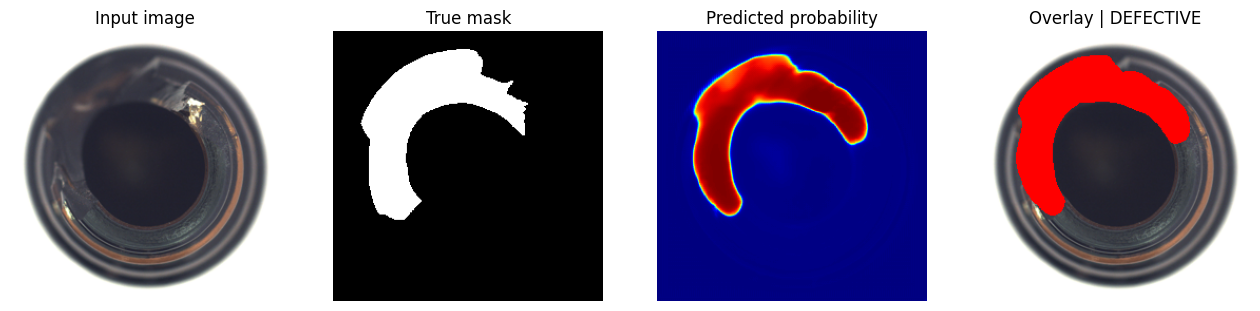

Verdict      : DEFECTIVE
Defect area  : 14.10% of image
Dice: 0.864 | IoU: 0.761

GOOD example: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle/test/good/000.png


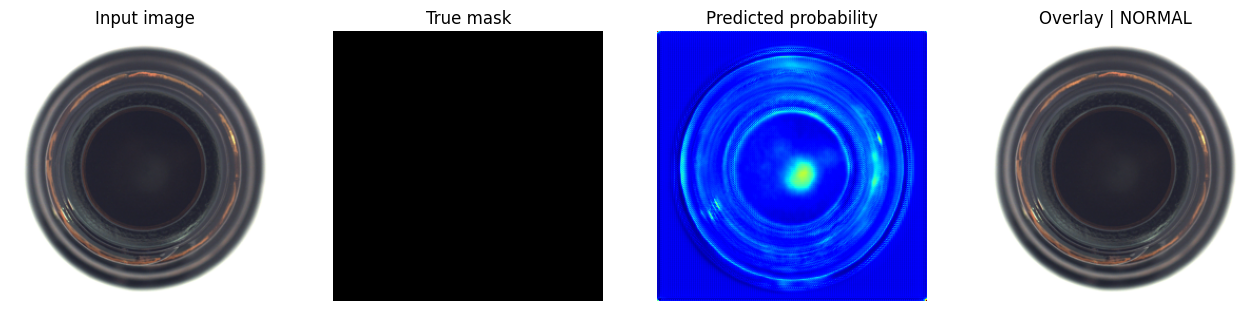

Verdict      : NORMAL
Defect area  : 0.00% of image


(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=uint8),
 array([[0.03403924, 0.0189781 , 0.01368584, ..., 0.01025653, 0.00784757,
         0.01558357],
        [0.01494693, 0.01167839, 0.00872884, ..., 0.00714975, 0.00753826,
         0.00926604],
        [0.00946493, 0.00765714, 0.00879594, ..., 0.00660411, 0.00567479,
         0.00773549],
        ...,
        [0.00862426, 0.00530563, 0.00398356, ..., 0.00859529, 0.01005345,
         0.01653383],
        [0.01234946, 0.00448668, 0.00225682, ..., 0.01210062, 0.02524842,
         0.02543006],
        [0.01935595, 0.01806539, 0.00603815, ..., 0.01330521, 0.02415164,
         0.03817609]], dtype=float32))

In [12]:
#testing single image
import matplotlib.pyplot as plt

# Loading the best saved model
model = UNet().to(device)
model.load_state_dict(torch.load("unet_bottle.pth", map_location=device))
model.eval()

def predict_single(image_path, mask_path=None, thr=0.5, min_pixels=20):
    img = Image.open(image_path).convert("RGB").resize((SIZE, SIZE))
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255
    x = x.unsqueeze(0).to(device)

    with torch.no_grad():
        prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()   
    pred = (prob > thr).astype(np.uint8)                      

    # Decision and defect size
    area_pct = pred.mean() * 100
    verdict = "DEFECTIVE" if pred.sum() >= min_pixels else "NORMAL"

    # Load true
    true = None
    if mask_path:
        true = (np.array(Image.open(mask_path).convert("L").resize((SIZE, SIZE), Image.NEAREST)) > 0).astype(np.uint8)
    elif mask_path is None:
        true = np.zeros((SIZE, SIZE), np.uint8)   


    dice = iou = None
    if true is not None and (true.sum() + pred.sum()) > 0:
        inter = (true * pred).sum()
        dice = 2 * inter / (true.sum() + pred.sum())
        iou = inter / (true.sum() + pred.sum() - inter)

    # Overlay: paint predicted defect red
    overlay = np.array(img).copy()
    overlay[pred == 1] = [255, 0, 0]

    # Ploting image
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    ax[0].imshow(img);                  ax[0].set_title("Input image")
    ax[1].imshow(true, cmap="gray");    ax[1].set_title("True mask")
    ax[2].imshow(prob, cmap="jet");     ax[2].set_title("Predicted probability")
    ax[3].imshow(overlay);              ax[3].set_title(f"Overlay | {verdict}")
    for a in ax: a.axis("off")
    plt.show()

    print(f"Verdict      : {verdict}")
    print(f"Defect area  : {area_pct:.2f}% of image")
    if dice is not None:
        print(f"Dice: {dice:.3f} | IoU: {iou:.3f}")
    return pred, prob

# Pick images from the TEST split 
defective_tests = [t for t in test if t[1] is not None]
good_tests      = [t for t in test if t[1] is None]

print("DEFECTIVE example:", defective_tests[0][0])
predict_single(defective_tests[0][0], defective_tests[0][1])

print("\nGOOD example:", good_tests[0][0])
predict_single(good_tests[0][0], None)